# LandscapeSHAP: how many Monte Carlo samples does it take?

The companion notebook (`landscapeshap_dynamical_systems.ipynb`) computes **exact**
point-level Shapley values for a linear model on persistence landscapes, in closed form,
with no sampling. This notebook asks the complementary question: if we did *not* have that
closed form and instead had to fall back on the generic, model-agnostic estimator described
in the write-up -- permutation sampling, honestly recomputing the landscape (with proper
re-ranking) for whatever sub-diagram a random permutation exposes at each step -- **how many
permutations would it take to approximate the true Shapley values well?**

This is a controlled experiment: we deliberately keep the same linear SVM as the companion
notebook, purely so that the exact closed-form values are available as ground truth to check
the sampler against. In practice this validated estimator is what you'd point at a genuinely
nonlinear model, where no ground truth exists to compare to.

This notebook:

1. Rebuilds the exact same dataset, landscape features, and linear SVM as the companion
   notebook (same random seed, so it's the same 500 point clouds and the same trained model).
2. Recomputes the exact, closed-form Shapley values for the 5 example diagrams as ground
   truth.
3. Implements a permutation-sampling Monte Carlo Shapley estimator against the **honest**
   coalition game (real re-ranked landscape recomputation per coalition, no shortcuts).
4. Runs a convergence study: estimation error vs. number of permutations, with repeated
   trials for variance, plus a wall-clock comparison against the closed form.


In [1]:
!pip install -q gudhi

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.5/4.5 MB 46.5 MB/s eta 0:00:00


In [2]:
import time
import numpy as np
import matplotlib.pyplot as plt
import gudhi
from collections import deque, defaultdict
from sklearn.svm import LinearSVC
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split

RNG_SEED = 42
rng = np.random.default_rng(RNG_SEED)


## 1. Dynamical system: sample the point clouds

$$x_{n+1} = x_n + r\cdot y_n(1-y_n) \bmod 1, \qquad y_{n+1} = y_n + r\cdot x_{n+1}(1-x_{n+1}) \bmod 1$$

Identical to the companion notebook, including the random seed, so this reproduces the same
500 point clouds and (after training below) the same model.


In [3]:
def sample_orbit(r, n_points=1000, burn_in=500, rng=None):
    """Iterate the coupled torus map and return n_points samples on the attractor."""
    rng = rng or np.random.default_rng()
    x, y = rng.uniform(), rng.uniform()
    for _ in range(burn_in):
        x = (x + r * y * (1.0 - y)) % 1.0
        y = (y + r * x * (1.0 - x)) % 1.0
    pts = np.empty((n_points, 2))
    for i in range(n_points):
        x = (x + r * y * (1.0 - y)) % 1.0
        y = (y + r * x * (1.0 - x)) % 1.0
        pts[i, 0] = x
        pts[i, 1] = y
    return pts

R_VALUES = [2.0, 3.5, 4.0, 4.1, 4.3]
N_CLOUDS_PER_R = 100
N_POINTS = 1000

point_clouds, labels = [], []
for r in R_VALUES:
    for _ in range(N_CLOUDS_PER_R):
        point_clouds.append(sample_orbit(r, n_points=N_POINTS, burn_in=500, rng=rng))
        labels.append(r)
labels = np.array(labels)
print(f"Generated {len(point_clouds)} point clouds, {N_POINTS} points each.")

EXAMPLE_INDICES = [int(np.where(labels == r)[0][0]) for r in R_VALUES]


Generated 500 point clouds, 1000 points each.


## 2. Persistent homology (H1, alpha complex)

Same construction as the companion notebook.

In [4]:
def compute_h1(points):
    """H1 persistence pairs for a 2D point cloud via the alpha complex.
    Returns a list of (birth, death, birth_simplex, death_simplex) tuples."""
    ac = gudhi.AlphaComplex(points=points)
    st = ac.create_simplex_tree()
    st.persistence(homology_coeff_field=2, min_persistence=0)
    h1 = []
    for birth_s, death_s in st.persistence_pairs():
        if len(birth_s) == 2 and len(death_s) == 3:
            b = np.sqrt(max(st.filtration(birth_s), 0.0))
            d = np.sqrt(max(st.filtration(death_s), 0.0))
            h1.append((b, d, birth_s, death_s))
    return h1

raw_h1 = [compute_h1(pc) for pc in point_clouds]

NOISE_FRAC = 0.02
all_deaths = np.concatenate([[p[1] for p in h1] for h1 in raw_h1 if h1])
GRID_MAX = float(np.percentile(all_deaths, 99) * 1.1)
EPSILON = NOISE_FRAC * GRID_MAX
M = 100
grid = np.linspace(0.0, GRID_MAX, M)
print(f"Grid max: {GRID_MAX:.4f}   noise threshold: {EPSILON:.5f}")

def filter_h1(h1):
    return [p for p in h1 if (p[1] - p[0]) > EPSILON]

h1_diagrams = [filter_h1(h1) for h1 in raw_h1]
print("Median / min / max surviving H1 features per cloud:",
      np.median([len(h) for h in h1_diagrams]),
      np.min([len(h) for h in h1_diagrams]),
      np.max([len(h) for h in h1_diagrams]))


Grid max: 0.0541   noise threshold: 0.00108
Median / min / max surviving H1 features per cloud: 320.0 1 376


## 3. Featurization: persistence landscapes

`K = 15` layers, same as the companion notebook.

In [5]:
K = 15

def landscape(h1, grid, K):
    N = len(h1)
    M = len(grid)
    if N == 0:
        return np.zeros((K, M))
    b = np.array([p[0] for p in h1])
    d = np.array([p[1] for p in h1])
    tent = np.minimum(np.maximum(0.0, grid[None, :] - b[:, None]),
                       np.maximum(0.0, d[:, None] - grid[None, :]))
    sorted_tent = np.sort(tent, axis=0)[::-1]
    L = np.zeros((K, M))
    L[:min(K, N)] = sorted_tent[:min(K, N)]
    return L

landscapes = [landscape(h1, grid, K).flatten() for h1 in h1_diagrams]
X = np.array(landscapes)
print("Feature matrix:", X.shape)


Feature matrix: (500, 1500)


## 4. Train a linear multiclass SVM

Same `r_to_label` string-encoding fix as the companion notebook (sklearn treats a raw float `r` array as a continuous/regression target).

In [6]:
def r_to_label(r):
    return f"{r:g}"

y = np.array([r_to_label(r) for r in labels])

X_train, X_test, y_train, y_test, idx_train, idx_test = train_test_split(
    X, y, np.arange(len(y)), test_size=0.25, stratify=y, random_state=RNG_SEED)

scaler = StandardScaler().fit(X_train)
X_train_s = scaler.transform(X_train)
X_test_s = scaler.transform(X_test)

model = LinearSVC(C=1.0, multi_class="ovr", max_iter=20000)
model.fit(X_train_s, y_train)
print("Test accuracy:", model.score(X_test_s, y_test))
print("Classes:", model.classes_)


Test accuracy: 0.792
Classes: ['2' '3.5' '4' '4.1' '4.3']


/usr/local/lib/python3.12/dist-packages/sklearn/svm/_base.py:1249: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(


## 5. Exact closed-form Shapley values (ground truth)

Identical machinery to the companion notebook (Theorem 1 / suffix-sum computation), reused
here purely to produce the ground truth this notebook checks the Monte Carlo estimator
against.


In [7]:
def order_stat_suffix(values):
    N = len(values)
    order = np.argsort(-values, kind="stable")
    tsort = values[order]
    tpad = np.append(tsort, 0.0)
    j = np.arange(1, N + 1)
    gaps = tpad[:-1] - tpad[1:]
    terms = gaps / j
    suffix = np.cumsum(terms[::-1])[::-1]
    return order, np.append(suffix, 0.0)

def column_all_layers_shapley(values, K, weights):
    N = len(values)
    if N == 0:
        return np.zeros(0)
    order, S = order_stat_suffix(values)
    rank_of = np.empty(N, dtype=int)
    rank_of[order] = np.arange(1, N + 1)
    contrib = np.zeros(N)
    for k in range(K):
        idx = np.maximum(rank_of, k + 1) - 1
        contrib += weights[k] * S[idx]
    return contrib

def point_shapley(h1, grid, K, w_landscape):
    N = len(h1)
    if N == 0:
        return np.zeros(0)
    b = np.array([p[0] for p in h1])
    d = np.array([p[1] for p in h1])
    phi = np.zeros(N)
    for m, gm in enumerate(grid):
        tent_m = np.minimum(np.maximum(0.0, gm - b), np.maximum(0.0, d - gm))
        phi += column_all_layers_shapley(tent_m, K, w_landscape[:, m])
    return phi

def rescaled_weights(model, scaler, class_label, K, M):
    c = list(model.classes_).index(class_label)
    w_full = model.coef_[c] / scaler.scale_
    return w_full.reshape(K, M), w_full

# Self-check against brute-force permutation enumeration (same check as the companion
# notebook -- confirms the closed form is implemented correctly in *this* environment).
import itertools

def brute_force_column_shapley(values, k):
    N = len(values)
    def v(idx_set):
        if len(idx_set) <= k:
            return 0.0
        return sorted((values[i] for i in idx_set), reverse=True)[k]
    phi = np.zeros(N)
    perms = list(itertools.permutations(range(N)))
    for perm in perms:
        coalition, v_prev = [], v([])
        for p in perm:
            coalition.append(p)
            v_cur = v(coalition)
            phi[p] += v_cur - v_prev
            v_prev = v_cur
    return phi / len(perms)

check_rng = np.random.default_rng(0)
max_err = 0.0
for _ in range(20):
    N = check_rng.integers(2, 6)
    vals = check_rng.uniform(0, 5, size=N)
    for k in range(N + 1):
        order, S = order_stat_suffix(vals)
        rank_of = np.empty(N, dtype=int)
        rank_of[order] = np.arange(1, N + 1)
        phi_cf = S[np.maximum(rank_of, k + 1) - 1]
        phi_bf = brute_force_column_shapley(vals, k)
        max_err = max(max_err, np.max(np.abs(phi_cf - phi_bf)))
print("Max abs error vs brute force:", max_err, "-> OK" if max_err < 1e-8 else "-> MISMATCH, stop and check")


Max abs error vs brute force: 2.220446049250313e-15 -> OK


## 6. The honest coalition game, and a Monte Carlo (permutation-sampling) estimator

For a subset $S$ of a diagram's points, the **honest** coalition value is the model's score
on the landscape recomputed from scratch on just those points -- real re-ranking, not a
frozen approximation. There is no shortcut for this at the level of an individual coalition;
the closed form in Section 5 only exists because it sums this quantity *analytically* over
all $2^N$ coalitions at once. Here we instead treat $v_f(S) = f(\mathrm{landscape}(S))$ as a
black box we can only *evaluate*, exactly as we would have to for a genuinely nonlinear
model, and estimate the Shapley value the standard way (Castro et al. 2009 / the strategy
described in the write-up): draw a random permutation of the diagram's points, walk through
it adding one point at a time, and attribute to each point the marginal change in $v_f$ at
the moment it joins. Averaging that marginal over many random permutations is an unbiased
estimator of the true Shapley value.

`coalition_value` below computes $v_f(S)$ directly from the raw per-point tent-value matrix
(sort the active rows, take the top $K$, dot with the model's weights) -- no closed form, a
fresh recomputation for every coalition, same as a nonlinear model's forward pass would
require.

**A faster version.** Walking a permutation re-sorts the *entire* growing coalition at every
step, which costs $O(|S|\log|S|)$ per step even though only the top $K$ values per column
ever matter. `mc_shapley_checkpoints` below instead maintains a running, sorted size-$K$
buffer per grid column: when a new point joins, its row is appended to the current buffer
(making it size $K{+}1$), that tiny array is re-sorted (cost independent of $|S|$), and it's
truncated back to $K$. This is the algorithm described in the write-up's efficient-computation
section for the general (non-closed-form) case -- it speeds up the featurization step for
*any* downstream model, linear or not, since it only concerns computing $\mathrm{landscape}(S)$
itself. `mc_shapley_checkpoints_naive` (the original full-resort version) is kept only as a
reference to verify the fast version against.


In [8]:
def tent_matrix(h1, grid):
    """Raw (N, M) tent values, one row per diagram point, un-sorted and untruncated --
    the honest per-point building block that column-wise sorting/truncation is applied to
    when a landscape is built from an arbitrary subset."""
    N = len(h1)
    Mlen = len(grid)
    if N == 0:
        return np.zeros((0, Mlen))
    b = np.array([p[0] for p in h1])
    d = np.array([p[1] for p in h1])
    return np.minimum(np.maximum(0.0, grid[None, :] - b[:, None]),
                       np.maximum(0.0, d[:, None] - grid[None, :]))

def coalition_value(tent_mat, w_KM, S_indices):
    """v_f(S): honestly recompute the K-layer landscape from just the rows in S_indices,
    then dot with the (already rescaled) linear weights. No closed form used here."""
    if len(S_indices) == 0:
        return 0.0
    sub = tent_mat[S_indices, :]
    sub_sorted = -np.sort(-sub, axis=0)          # each column re-ranked within S alone
    Kc = w_KM.shape[0]
    n = sub_sorted.shape[0]
    if n >= Kc:
        top = sub_sorted[:Kc, :]
    else:
        top = np.vstack([sub_sorted, np.zeros((Kc - n, sub_sorted.shape[1]))])
    return float(np.sum(top * w_KM))

# Sanity check: coalition_value on the full point set must reproduce the same raw score
# that the closed-form point_shapley values sum to (the efficiency axiom).
check_idx = EXAMPLE_INDICES[0]
h1_c = h1_diagrams[check_idx]
w_land_c, w_full_c = rescaled_weights(model, scaler, r_to_label(labels[check_idx]), K, M)
phi_c = point_shapley(h1_c, grid, K, w_land_c)
tent_c = tent_matrix(h1_c, grid)
v_full = coalition_value(tent_c, w_land_c, np.arange(len(h1_c)))
v_empty = coalition_value(tent_c, w_land_c, np.array([], dtype=int))
print(f"sum(phi_exact) = {phi_c.sum():.6f}   v(full)-v(empty) = {v_full - v_empty:.6f}   "
      f"|diff| = {abs(phi_c.sum() - (v_full - v_empty)):.2e}")


sum(phi_exact) = 2.839922   v(full)-v(empty) = 2.839922   |diff| = 4.44e-16


In [9]:
def mc_shapley_checkpoints_naive(tent_mat, w_KM, checkpoints, rng):
    """Permutation-sampling Shapley estimator, full-resort version. Runs checkpoints[-1]
    permutations in one pass, recording the running average estimate at each requested
    checkpoint so a single run yields the whole convergence trajectory (rather than
    restarting from scratch for every sample-count we want to inspect). Re-sorts the entire
    growing coalition at every step -- O(|S| log|S|) per step -- kept only as a correctness
    reference for the fast version below."""
    N = tent_mat.shape[0]
    phi_accum = np.zeros(N)
    results = {}
    ci = 0
    max_n = checkpoints[-1]
    for n in range(1, max_n + 1):
        perm = rng.permutation(N)
        S_list = []
        prev_val = 0.0
        for idx in perm:
            S_list.append(idx)
            new_val = coalition_value(tent_mat, w_KM, np.array(S_list))
            phi_accum[idx] += new_val - prev_val
            prev_val = new_val
        if ci < len(checkpoints) and n == checkpoints[ci]:
            results[n] = phi_accum.copy() / n
            ci += 1
    return results

def mc_shapley_checkpoints(tent_mat, w_KM, checkpoints, rng):
    """Same estimator, but maintains a running sorted size-K buffer per grid column
    instead of re-sorting the whole growing coalition at every step. When a new point
    joins, its row is appended to the current buffer (size K -> K+1), that tiny array is
    re-sorted (cost independent of |S|), and truncated back to K -- see the write-up's
    efficient-computation section for the algorithm and complexity argument. Verified
    against mc_shapley_checkpoints_naive below."""
    N, M = tent_mat.shape
    Kc = w_KM.shape[0]
    phi_accum = np.zeros(N)
    results = {}
    ci = 0
    max_n = checkpoints[-1]
    for n in range(1, max_n + 1):
        perm = rng.permutation(N)
        buf = np.zeros((0, M))
        prev_val = 0.0
        for idx in perm:
            row = tent_mat[idx:idx + 1, :]
            cand = np.vstack([buf, row])
            cand_sorted = -np.sort(-cand, axis=0)
            buf = cand_sorted[:Kc, :]
            new_val = float(np.sum(buf * w_KM[:buf.shape[0], :]))
            phi_accum[idx] += new_val - prev_val
            prev_val = new_val
        if ci < len(checkpoints) and n == checkpoints[ci]:
            results[n] = phi_accum.copy() / n
            ci += 1
    return results

# Correctness check: with matching seeds, both functions draw the identical sequence of
# permutations, so they must agree to floating-point precision if the fast version is a
# faithful reimplementation -- not just "close", exactly equal.
check_idx3 = EXAMPLE_INDICES[0]
h1_chk = h1_diagrams[check_idx3]
w_land_chk, _ = rescaled_weights(model, scaler, r_to_label(labels[check_idx3]), K, M)
tent_chk = tent_matrix(h1_chk, grid)

res_naive = mc_shapley_checkpoints_naive(tent_chk, w_land_chk, [50], np.random.default_rng(999))
res_fast = mc_shapley_checkpoints(tent_chk, w_land_chk, [50], np.random.default_rng(999))
diff = np.max(np.abs(res_naive[50] - res_fast[50]))
print(f"Naive vs. fast estimator, same permutation sequence, n=50: max abs diff = {diff:.2e}",
      "-> OK" if diff < 1e-9 else "-> MISMATCH, stop and check")


Naive vs. fast estimator, same permutation sequence, n=50: max abs diff = 2.78e-17 -> OK


## 7. Convergence experiment: how many permutations are needed?

For each of the 5 example diagrams, we run several independent Monte Carlo estimators
(different random seeds) up to `CHECKPOINTS[-1]` permutations, recording the running estimate
at each checkpoint. Against the exact closed-form values we track: **mean absolute error**,
the same error **normalized** by the average |Shapley value| for that diagram (so diagrams of
different scale are comparable), and the **Pearson correlation** between the MC estimate and
the exact values (a looser check: does the sampler at least get the relative
ordering/direction right, even before the magnitudes have converged).

Runtime scales roughly linearly in both the number of permutations and the diagram size $N$
now that `mc_shapley_checkpoints` uses the size-$K$ buffer (each permutation does $N$
marginal evaluations, each a small, $|S|$-independent sort) -- markedly better than the
naive version's quadratic-in-$N$ scaling. Still, reduce `CHECKPOINTS[-1]` or `N_REPEATS`
below if a diagram turns out unusually large.


In [10]:
CHECKPOINTS = [10, 30, 100, 300, 1000, 3000]
N_REPEATS = 8

example_indices = [idx for idx in EXAMPLE_INDICES if len(h1_diagrams[idx]) > 0]

mc_results = {}
for idx in example_indices:
    h1 = h1_diagrams[idx]
    true_r = labels[idx]
    w_land, w_full = rescaled_weights(model, scaler, r_to_label(true_r), K, M)
    phi_exact = point_shapley(h1, grid, K, w_land)
    tent_mat = tent_matrix(h1, grid)
    N_pts = len(h1)
    scale = max(np.mean(np.abs(phi_exact)), 1e-12)

    err_by_n = {n: [] for n in CHECKPOINTS}
    corr_by_n = {n: [] for n in CHECKPOINTS}
    last_run = None
    t0 = time.time()
    for rep in range(N_REPEATS):
        rng_mc = np.random.default_rng(10_000 * idx + rep)
        res = mc_shapley_checkpoints(tent_mat, w_land, CHECKPOINTS, rng_mc)
        last_run = res
        for n in CHECKPOINTS:
            err_by_n[n].append(np.mean(np.abs(res[n] - phi_exact)))
            corr_by_n[n].append(1.0 if N_pts < 2 else np.corrcoef(res[n], phi_exact)[0, 1])
    elapsed = time.time() - t0

    mc_results[idx] = dict(N=N_pts, r=true_r, phi_exact=phi_exact, scale=scale,
                            err_by_n=err_by_n, corr_by_n=corr_by_n,
                            mc_at_max_n=last_run[CHECKPOINTS[-1]])
    print(f"r={true_r:>4}  N={N_pts:4d} points  "
          f"mean_abs_err@n={CHECKPOINTS[-1]}: {np.mean(err_by_n[CHECKPOINTS[-1]]):.5f} "
          f"(normalized: {np.mean(err_by_n[CHECKPOINTS[-1]]) / scale:.4f})  "
          f"[{N_REPEATS} repeats, {elapsed:.1f}s]")


r= 2.0  N= 264 points  mean_abs_err@n=3000: 0.00040 (normalized: 0.0238)  [8 repeats, 187.9s]
r= 3.5  N= 337 points  mean_abs_err@n=3000: 0.00069 (normalized: 0.0670)  [8 repeats, 235.6s]
r= 4.0  N= 317 points  mean_abs_err@n=3000: 0.00112 (normalized: 0.0458)  [8 repeats, 217.0s]
r= 4.1  N= 313 points  mean_abs_err@n=3000: 0.00105 (normalized: 0.0381)  [8 repeats, 210.5s]
r= 4.3  N= 312 points  mean_abs_err@n=3000: 0.00091 (normalized: 0.0376)  [8 repeats, 209.9s]


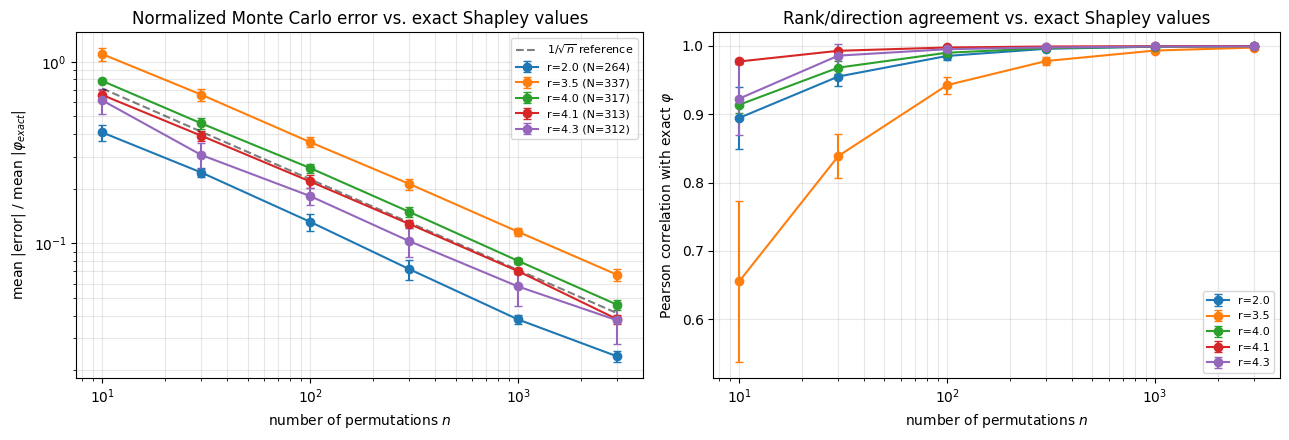

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

for idx in example_indices:
    res = mc_results[idx]
    means = [np.mean(res['err_by_n'][n]) / res['scale'] for n in CHECKPOINTS]
    stds = [np.std(res['err_by_n'][n]) / res['scale'] for n in CHECKPOINTS]
    axes[0].errorbar(CHECKPOINTS, means, yerr=stds, marker="o", capsize=3,
                      label=f"r={res['r']} (N={res['N']})")

    corr_means = [np.mean(res['corr_by_n'][n]) for n in CHECKPOINTS]
    corr_stds = [np.std(res['corr_by_n'][n]) for n in CHECKPOINTS]
    axes[1].errorbar(CHECKPOINTS, corr_means, yerr=corr_stds, marker="o", capsize=3,
                      label=f"r={res['r']}")

# reference 1/sqrt(n) slope for comparison, anchored at the first checkpoint's mean error
ref_x = np.array(CHECKPOINTS, dtype=float)
first_vals = [np.mean(mc_results[idx]['err_by_n'][CHECKPOINTS[0]]) / mc_results[idx]['scale']
              for idx in example_indices]
ref_y0 = np.mean(first_vals)
axes[0].plot(ref_x, ref_y0 * np.sqrt(ref_x[0] / ref_x), "k--", alpha=0.5, label=r"$1/\sqrt{n}$ reference")

axes[0].set_xscale("log"); axes[0].set_yscale("log")
axes[0].set_xlabel("number of permutations $n$")
axes[0].set_ylabel(r"mean |error| / mean |$\varphi_{exact}$|")
axes[0].set_title("Normalized Monte Carlo error vs. exact Shapley values")
axes[0].legend(fontsize=8)
axes[0].grid(alpha=0.3, which="both")

axes[1].set_xscale("log")
axes[1].set_xlabel("number of permutations $n$")
axes[1].set_ylabel(r"Pearson correlation with exact $\varphi$")
axes[1].set_title("Rank/direction agreement vs. exact Shapley values")
axes[1].legend(fontsize=8)
axes[1].grid(alpha=0.3, which="both")
axes[1].set_ylim(top=1.02)

plt.tight_layout()
fig.savefig("mc_convergence.svg", format="svg", bbox_inches="tight")
plt.show()


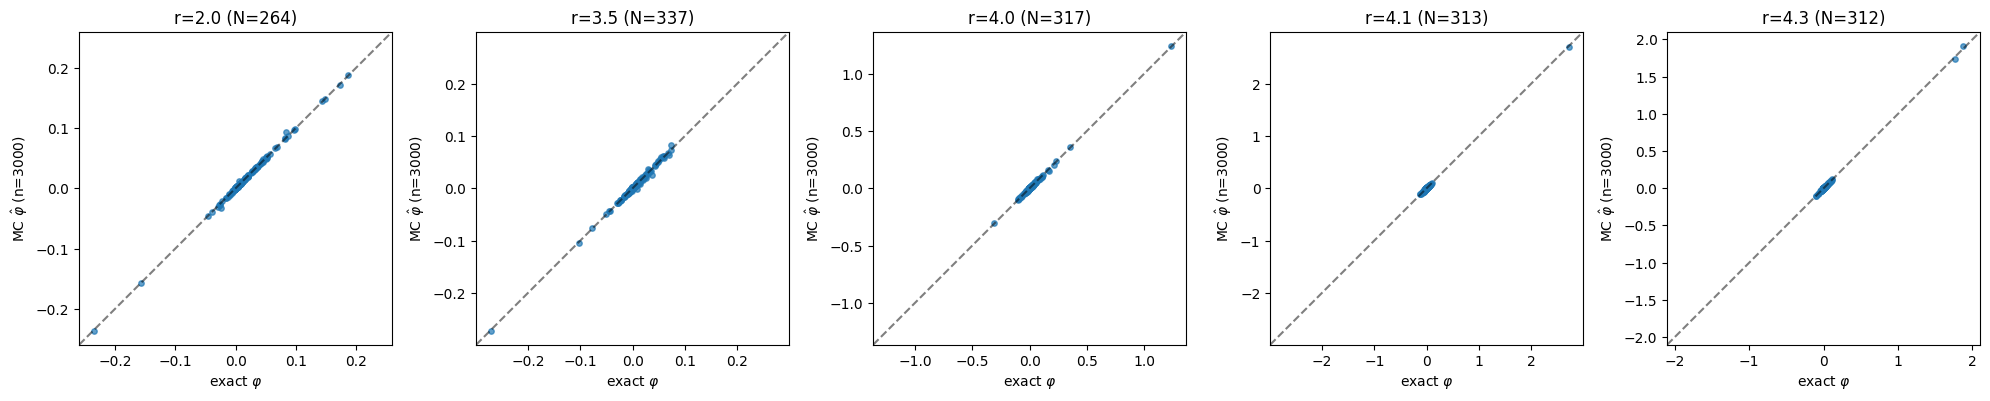

In [12]:
# Calibration check: exact vs. Monte Carlo estimate at the largest checkpoint, one panel
# per example diagram. Points on the diagonal are estimated correctly.
fig, axes = plt.subplots(1, len(example_indices), figsize=(4 * len(example_indices), 4))
if len(example_indices) == 1:
    axes = [axes]

for ax, idx in zip(axes, example_indices):
    res = mc_results[idx]
    exact = res['phi_exact']
    approx = res['mc_at_max_n']
    lim = max(np.max(np.abs(exact)), np.max(np.abs(approx)), 1e-8) * 1.1
    ax.scatter(exact, approx, s=15, alpha=0.7)
    ax.plot([-lim, lim], [-lim, lim], "k--", alpha=0.5)
    ax.set_xlim(-lim, lim); ax.set_ylim(-lim, lim)
    ax.set_xlabel(r"exact $\varphi$"); ax.set_ylabel(rf"MC $\hat\varphi$ (n={CHECKPOINTS[-1]})")
    ax.set_title(f"r={res['r']} (N={res['N']})")
    ax.set_aspect("equal")

plt.tight_layout()
fig.savefig("mc_calibration.svg", format="svg", bbox_inches="tight")
plt.show()


In [13]:
# Wall-clock: exact closed form vs. Monte Carlo, on the largest example diagram.
idx_big = max(example_indices, key=lambda i: len(h1_diagrams[i]))
h1_big = h1_diagrams[idx_big]
w_land_big, _ = rescaled_weights(model, scaler, r_to_label(labels[idx_big]), K, M)
tent_big = tent_matrix(h1_big, grid)

t0 = time.time()
for _ in range(20):
    point_shapley(h1_big, grid, K, w_land_big)
t_exact = (time.time() - t0) / 20

timing_checkpoints = [10, 100, 1000]
t_mc_fast, t_mc_naive = {}, {}
for n in timing_checkpoints:
    t0 = time.time()
    mc_shapley_checkpoints(tent_big, w_land_big, [n], np.random.default_rng(0))
    t_mc_fast[n] = time.time() - t0

    t0 = time.time()
    mc_shapley_checkpoints_naive(tent_big, w_land_big, [n], np.random.default_rng(0))
    t_mc_naive[n] = time.time() - t0

print(f"Diagram size: N={len(h1_big)} points")
print(f"Exact closed-form: {t_exact*1000:.3f} ms (one call, all {len(h1_big)} points x {K} layers x {M} grid points)")
for n in timing_checkpoints:
    print(f"Monte Carlo, n={n:5d} permutations: "
          f"naive {t_mc_naive[n]:8.3f}s ({t_mc_naive[n] / t_exact:,.0f}x closed-form)   "
          f"fast {t_mc_fast[n]:8.3f}s ({t_mc_fast[n] / t_exact:,.0f}x closed-form)   "
          f"speedup {t_mc_naive[n] / t_mc_fast[n]:.1f}x")


Diagram size: N=337 points
Exact closed-form: 13.069 ms (one call, all 337 points x 15 layers x 100 grid points)
Monte Carlo, n=   10 permutations: naive    0.452s (35x closed-form)   fast    0.093s (7x closed-form)   speedup 4.9x
Monte Carlo, n=  100 permutations: naive    4.466s (342x closed-form)   fast    0.946s (72x closed-form)   speedup 4.7x
Monte Carlo, n= 1000 permutations: naive   45.036s (3,446x closed-form)   fast    9.540s (730x closed-form)   speedup 4.7x


## Notes on design choices / caveats

- **Why the ground truth is available here.** This experiment only works as a validation
  check because the model is linear, so Section 5's closed form gives an exact target to
  measure error against. For a genuinely nonlinear model there is no such target -- this is
  exactly why the write-up frames the Monte Carlo estimator as the fallback for that setting,
  and why validating its convergence behavior here (where we *can* check it) matters before
  trusting it there (where we can't).
- **What "honest" means.** `coalition_value` recomputes the landscape from scratch for every
  sampled coalition -- real re-ranking of whichever points happen to be in $S$, not a frozen
  ownership/baseline-substitution shortcut. This is deliberately the expensive, correct
  version; it's what makes the estimator target the same quantity as the closed form instead
  of a biased approximation of it.
- **Runtime.** `CHECKPOINTS[-1]` and `N_REPEATS` are set conservatively so the whole notebook
  finishes in a reasonable time; extend either for smoother convergence curves and tighter
  variance bands. Runtime now scales roughly linearly in permutations *and* in diagram size
  $N$ (Section 6's buffer-based `mc_shapley_checkpoints`), rather than quadratically in $N$
  as the naive full-resort version does -- the timing cell above prints the naive-vs-fast
  speedup directly on your largest example diagram.
- **Diagram-to-diagram variation.** Convergence speed depends on diagram size $N$ (more
  players -> more permutations needed for the same relative accuracy) and on how spread out
  the true Shapley values are (a diagram dominated by a few large-|$\varphi$| points tends to
  show correlation converge faster than magnitude does, since the estimator gets the ranking
  right well before the exact values stabilize) -- both visible by comparing curves across
  the five `r` values above.
- **Correlation metric.** Pearson correlation is used rather than Spearman purely to avoid a
  `scipy` dependency; swap in `scipy.stats.spearmanr` if a pure rank-agreement metric is
  preferred.
- **Figures.** The convergence plot and calibration scatter are also saved as
  `mc_convergence.svg` and `mc_calibration.svg` in the working directory, for use directly
  in the write-up.
